# Google Trends: before, during, and after the peak

Four search terms in the Philippines. Find the peak, compare nearby weeks, then check regions.
Sections 8 and 9 build higher-resolution series for forecasting and rerun the small GPU model on them;
`google_trends_ml.ipynb` compares that model with ARIMA, XGBoost and random forests.

Run top to bottom. Dates are fixed to match the original notebook; change `END_DATE` for a newer run.

## 1. Setup

Run this once if the packages are missing.


In [1]:
# Packages are already installed in the repository .venv.
# For a fresh environment, uncomment and run these in the selected kernel:
# %pip install --upgrade pip
# %pip install "numpy>=2.0,<3" "pandas>=2.2,<4" "matplotlib>=3.9,<4" pytrends==4.9.2 "ipykernel>=6.29,<8" "scikit-learn>=1.6,<2"
# %pip install "xgboost>=3.1,<4" "statsmodels>=0.14,<1"  # used by google_trends_ml.ipynb
# %pip install torch==2.13.0 --index-url https://download.pytorch.org/whl/cu130
# Restart the kernel after installation, then run from the top.

In [2]:
import csv
import io
import json
import time
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

try:
    from pytrends.request import TrendReq
    PYTRENDS_AVAILABLE = True
except ImportError:
    PYTRENDS_AVAILABLE = False
    print("pytrends is missing. Install it above, or use manual CSV exports.")


### GPU setup and verification

Select **Tagatrend GPU (.venv)** in the kernel picker. All ML code lives in this notebook.
The setup cell above installs into the selected kernel's Python environment.

The RTX 5050 uses Blackwell compute capability 12.0. PyTorch 2.13.0's CUDA 13.0
Windows wheel supports it, and your installed NVIDIA driver is 610.71. The CUDA
number in `nvidia-smi` describes driver compatibility; `torch.version.cuda` describes
the wheel's runtime. These prebuilt wheels need no separate CUDA Toolkit.
Sources: [PyTorch installation](https://pytorch.org/get-started/previous-versions/),
[Blackwell support](https://pytorch.org/blog/pytorch-2-7/),
[NVIDIA GPU capabilities](https://developer.nvidia.com/cuda/gpus).

The next cell tests actual forward, backward, and optimizer updates on CUDA.
Training requires `cuda:0` and fails clearly if CUDA is unavailable. CSV processing
and Python orchestration use the CPU; ordinary scikit-learn estimators use CPU too.

In [3]:
"""Require CUDA and verify an actual training step, rather than detection alone."""
import json

import torch


# Return the GPU device, or stop with a clear message if CUDA is unavailable (no CPU fallback).
def require_cuda():
    if not torch.cuda.is_available():
        raise RuntimeError(
            "CUDA is unavailable; CPU training is disabled. Use the repository .venv, "
            "run the CUDA installation command in the setup cell, and run nvidia-smi to check the driver."
        )
    return torch.device("cuda:0")


# Run a real forward, backward and optimizer step on the GPU, then report the GPU's details.
# Proves training works, not just that a GPU is detected.
def check_gpu():
    device = require_cuda()
    model = torch.nn.Sequential(torch.nn.Linear(16, 32), torch.nn.ReLU(),
                                torch.nn.Linear(32, 1)).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
    inputs = torch.randn(64, 16, device=device)
    targets = torch.randn(64, 1, device=device)
    before = model[0].weight.detach().clone()
    for _ in range(3):
        optimizer.zero_grad(set_to_none=True)
        loss = torch.nn.functional.mse_loss(model(inputs), targets)
        loss.backward()
        optimizer.step()
    torch.cuda.synchronize()
    if not torch.isfinite(loss) or torch.equal(before, model[0].weight):
        raise RuntimeError("CUDA training smoke test failed.")
    return {
        "torch": torch.__version__, "cuda_runtime": torch.version.cuda,
        "gpu": torch.cuda.get_device_name(device),
        "compute_capability": list(torch.cuda.get_device_capability(device)),
        "compiled_architectures": torch.cuda.get_arch_list(),
        "vram_gib": round(torch.cuda.get_device_properties(device).total_memory / 2**30, 2),
        "model_device": str(next(model.parameters()).device),
        "training_step_passed": True,
    }


import sys
print("Kernel Python:", sys.executable)
gpu_info = check_gpu()
display(pd.Series(gpu_info, name="GPU verification"))

Kernel Python: c:\Users\Admin\OneDrive\Documents\GitHub\tagatrend\.venv\Scripts\python.exe


torch                                                     2.13.0+cu130
cuda_runtime                                                      13.0
gpu                                 NVIDIA GeForce RTX 5050 Laptop GPU
compute_capability                                             [12, 0]
compiled_architectures    [sm_75, sm_80, sm_86, sm_90, sm_100, sm_120]
vram_gib                                                          7.96
model_device                                                    cuda:0
training_step_passed                                              True
Name: GPU verification, dtype: object

In [4]:
GEO = "PH"
END_DATE = "2026-09-25"
REFRESH = False  # True: request fresh data instead of using saved files.
RUN_REGIONS = True

DATA_DIR = Path("data")
RAW_DIR = DATA_DIR / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)

trends = pd.DataFrame([
    {"slug": "sana_all", "query": "Sana All", "start": "2018-01-01"},
    {"slug": "pabebe_girls", "query": "Pabebe Girls", "start": "2015-01-01"},
    {"slug": "never_grow_old", "query": "Never Grow Old", "start": "2026-08-15"},
    {"slug": "fox_silica", "query": "Fox Silica", "start": "2026-07-15"},
])
trends["end"] = END_DATE

display(trends[["query", "start", "end"]])


,query,start,end
0,Sana All,2018-01-01,2026-09-25
1,Pabebe Girls,2015-01-01,2026-09-25
2,Never Grow Old,2026-08-15,2026-09-25
3,Fox Silica,2026-07-15,2026-09-25


These are search terms, not confirmed trend origins. Start dates only set the search window.

Scores show relative interest, not search counts. Each request has its own scale. A zero can mean too little data. [Google's guide](https://support.google.com/trends/answer/4365533?hl=en)


## 2. Load the data

Use a matching saved file first, then pytrends, then a manual export.

For manual data, export **Interest over time** or **Interest by subregion** from Google Trends. Match the printed query, PH, and dates. Save to the path printed on failure. Use one search term per export.

Three helpers handle repeated file and request work. The analysis stays in separate cells.


In [5]:
# Read a CSV exported by hand from the Google Trends website.
# Skips Google's title rows, keeps one search term, and turns "<1" into 0.5.
def read_manual_export(path, kind):
    lines = path.read_text(encoding="utf-8-sig").splitlines()
    header_row = None

    if kind == "time":
        headers = {"date", "day", "week", "month"}
    else:
        headers = {"region", "subregion", "geoname", "country"}

    for row_number, line in enumerate(lines):
        fields = next(csv.reader([line]))
        if fields and fields[0].strip().lower() in headers:
            header_row = row_number
            break

    if header_row is None:
        raise ValueError("No date or region header found. Use an English Google Trends export.")

    frame = pd.read_csv(io.StringIO("\n".join(lines[header_row:])))
    frame = frame.dropna(how="all")
    if len(frame.columns) != 2:
        raise ValueError("Export exactly one search term.")

    frame.columns = ["label", "interest"]
    # Google reports <1 as a range. Use 0.5 as an approximation.
    values = frame["interest"].astype(str).str.strip()
    values = values.replace({"<1": "0.5", "< 1": "0.5"})
    frame["interest"] = pd.to_numeric(values, errors="coerce")

    if kind == "time":
        frame["label"] = pd.to_datetime(frame["label"], errors="raise")
    return frame.set_index("label")

In [6]:
# Ask Google Trends (via pytrends) for one query and date window.
# kind="time" gives interest over time; anything else gives interest by region.
# Retries only when Google rate-limits the request (HTTP 429).
def request_trends(query, window, kind):
    if not PYTRENDS_AVAILABLE:
        raise RuntimeError("pytrends is not installed")

    for attempt in range(3):
        try:
            client = TrendReq(hl="en-PH", tz=-480, timeout=(10, 30))
            client.build_payload([query], timeframe=window, geo=GEO)

            if kind == "time":
                frame = client.interest_over_time()
            else:
                frame = client.interest_by_region(
                    resolution="REGION", inc_low_vol=True, inc_geo_code=False
                )

            if frame.empty:
                raise ValueError("Google returned no data")
            time.sleep(1)
            return frame
        except Exception as error:
            response = getattr(error, "response", None)
            status = getattr(response, "status_code", None)
            if status == 429 and attempt < 2:
                delay = 5 * (attempt + 1)
                print(f"Rate limit. Trying again in {delay} seconds.")
                time.sleep(delay)
            else:
                raise

In [7]:
# Get one query/window/kind: use the saved CSV if its metadata matches, otherwise request it,
# otherwise fall back to a manual export. Saves the result and its metadata for next time.
def load_trends(slug, query, start, end, kind="time"):
    window = f"{start} {end}"
    filename = f"{slug}_{kind}_{start}_{end}"
    csv_path = RAW_DIR / f"{filename}.csv"
    json_path = RAW_DIR / f"{filename}.json"
    manual_path = DATA_DIR / f"{filename}.csv"
    expected = {"query": query, "geo": GEO, "window": window, "kind": kind}

    if pd.Timestamp(start) > pd.Timestamp(end):
        raise ValueError("Start date must be on or before the end date.")

    if csv_path.exists() and json_path.exists() and not REFRESH:
        saved = json.loads(json_path.read_text(encoding="utf-8"))
        matches = True
        for key, value in expected.items():
            if saved.get(key) != value:
                matches = False
        if matches:
            print(f"{query}: saved {kind} data ({window})")
            return pd.read_csv(csv_path, index_col=0)

    try:
        frame = request_trends(query, window, kind)
        source = "pytrends"
    except Exception as error:
        print(f"{query}, PH, {window}: {error}")
        if manual_path.exists():
            frame = read_manual_export(manual_path, kind)
            source = "manual CSV"
        else:
            print(f"Save the matching export to: {manual_path}")
            return None

    saved = expected.copy()
    saved["source"] = source
    saved["extracted_utc"] = datetime.now(timezone.utc).isoformat(timespec="seconds")
    frame.to_csv(csv_path)
    json_path.write_text(json.dumps(saved, indent=2), encoding="utf-8")
    print(f"{query}: {len(frame)} rows from {source}")
    return frame

In [8]:
raw_data = {}

for trend in trends.itertuples(index=False):
    frame = load_trends(trend.slug, trend.query, trend.start, trend.end)
    if frame is not None:
        raw_data[trend.slug] = frame

if not raw_data:
    print("No data loaded. Add the exports above, then rerun from this cell.")


Sana All: saved time data (2018-01-01 2026-09-25)
Pabebe Girls: saved time data (2015-01-01 2026-09-25)
Never Grow Old: saved time data (2026-08-15 2026-09-25)
Fox Silica: saved time data (2026-07-15 2026-09-25)


## 3. Check coverage and find the peak period

Drop rows Google marks unfinished. Keep missing values as missing.

Monthly rows identify a peak month, not a peak day. If peaks tie, use the earliest one.


In [9]:
data = {}
partial_counts = {}

for trend in trends.itertuples(index=False):
    if trend.slug not in raw_data:
        continue

    frame = raw_data[trend.slug].copy()
    frame.index = pd.to_datetime(frame.index)
    frame = frame.sort_index()
    partial_rows = 0
    if "isPartial" in frame.columns:
        partial = frame["isPartial"].astype(str).str.lower() == "true"
        partial_rows = int(partial.sum())
        frame = frame.loc[~partial].drop(columns="isPartial")

    if len(frame.columns) != 1 or frame.index.has_duplicates:
        print(f"{trend.query}: expected one series with unique dates; skipped.")
        continue

    series = pd.to_numeric(frame.iloc[:, 0], errors="coerce")
    series = series.loc[trend.start:trend.end]
    series = series.where(series.between(0, 100))
    valid = series.dropna()
    if valid.empty:
        print(f"{trend.query}: no usable values.")
        continue

    data[trend.slug] = series
    partial_counts[trend.slug] = partial_rows


In [10]:
peak_periods = {}
overview_rows = []

for trend in trends.itertuples(index=False):
    if trend.slug not in data:
        continue

    series = data[trend.slug]
    valid = series.dropna()
    spacing = series.index.to_series().diff().dt.days.median()
    if spacing == 1:
        frequency = "Daily"
    elif spacing == 7:
        frequency = "Weekly"
    elif 28 <= spacing <= 31:
        frequency = "Monthly"
    else:
        frequency = "Irregular / unknown"

    peak_label = "No positive peak"
    if valid.max() > 0:
        peak_start = valid.idxmax()
        if frequency == "Monthly":
            peak_end = peak_start + pd.DateOffset(months=1) - pd.Timedelta(days=1)
        elif frequency == "Weekly":
            peak_end = peak_start + pd.Timedelta(days=6)
        else:
            peak_end = peak_start

        peak_label = f"{peak_start:%Y-%m-%d} to {peak_end:%Y-%m-%d}"
        if frequency != "Irregular / unknown":
            peak_periods[trend.slug] = (peak_start, peak_end)

    overview_rows.append({
        "Trend": trend.query,
        "Frequency": frequency,
        "First row": f"{series.index.min():%Y-%m-%d}",
        "Last row": f"{series.index.max():%Y-%m-%d}",
        "Missing values": int(series.isna().sum()),
        "Partial rows removed": partial_counts[trend.slug],
        "Peak period": peak_label,
        "Latest score": valid.iloc[-1],
    })

overview = pd.DataFrame(overview_rows)
display(overview)


,Trend,Frequency,First row,Last row,Missing values,Partial rows removed,Peak period,Latest score
0,Sana All,Monthly,2018-01-01,2026-09-01,0,0,2019-11-01 to 2019-11-30,6
1,Pabebe Girls,Monthly,2015-01-01,2026-09-01,0,0,2015-07-01 to 2015-07-31,0
2,Never Grow Old,Daily,2026-08-15,2026-09-25,0,0,2026-09-11 to 2026-09-11,0
3,Fox Silica,Daily,2026-07-15,2026-09-25,0,0,2026-07-29 to 2026-07-29,0


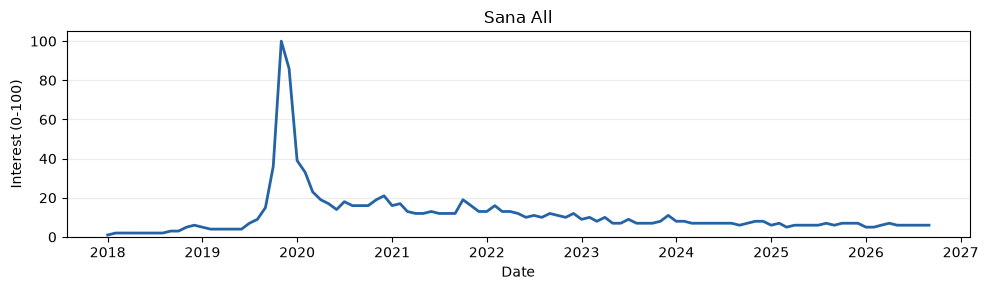

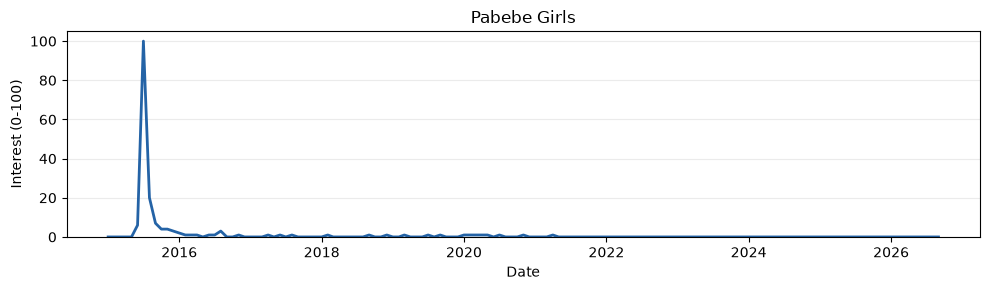

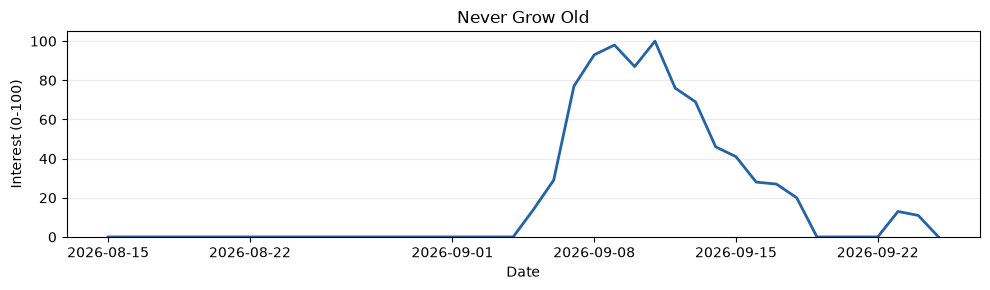

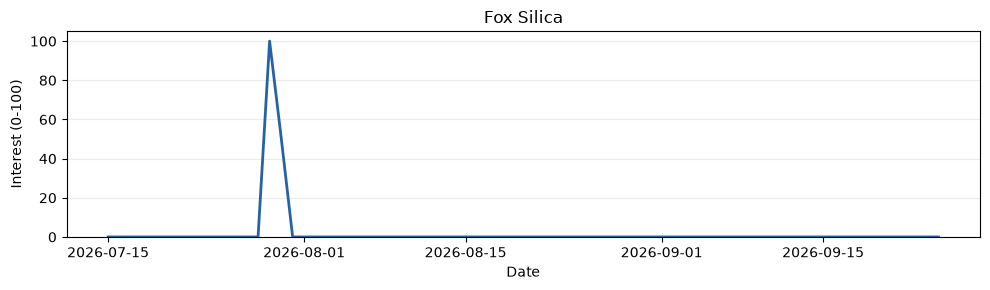

In [11]:
for trend in trends.itertuples(index=False):
    if trend.slug not in data:
        continue

    series = data[trend.slug]
    fig, ax = plt.subplots(figsize=(10, 3))
    ax.plot(series.index, series, color="#2463a6", linewidth=2)
    ax.set(title=trend.query, xlabel="Date", ylabel="Interest (0-100)", ylim=(0, 105))
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()
    plt.show()


## 4. Zoom in on the peak

Request daily data around the strongest period, with three weeks on either side.
Find the highest day **inside that period**. This is a local peak; a different month could contain a higher single day.

Use one daily request per trend so nearby weeks share the same scale. Do not compare these scores with the full-history scores.


In [12]:
zoom_data = {}

for trend in trends.itertuples(index=False):
    if trend.slug not in peak_periods:
        continue

    peak_start, peak_end = peak_periods[trend.slug]
    zoom_start = peak_start - pd.Timedelta(days=21)
    zoom_end = peak_end + pd.Timedelta(days=21)
    if zoom_start < pd.Timestamp("2004-01-01"):
        zoom_start = pd.Timestamp("2004-01-01")
    if zoom_end > pd.Timestamp(END_DATE):
        zoom_end = pd.Timestamp(END_DATE)

    frame = load_trends(
        trend.slug, trend.query,
        f"{zoom_start:%Y-%m-%d}", f"{zoom_end:%Y-%m-%d}",
    )
    if frame is not None:
        zoom_data[trend.slug] = frame


Sana All: saved time data (2019-10-11 2019-12-21)
Pabebe Girls: saved time data (2015-06-10 2015-08-21)
Never Grow Old: saved time data (2026-08-21 2026-09-25)
Fox Silica: saved time data (2026-07-08 2026-08-19)


In [13]:
daily_data = {}
peak_days = {}
peak_day_rows = []

for trend in trends.itertuples(index=False):
    if trend.slug not in zoom_data:
        continue

    frame = zoom_data[trend.slug].copy()
    frame.index = pd.to_datetime(frame.index)
    frame = frame.sort_index()
    if "isPartial" in frame.columns:
        partial = frame["isPartial"].astype(str).str.lower() == "true"
        frame = frame.loc[~partial].drop(columns="isPartial")

    if len(frame.columns) != 1 or frame.index.has_duplicates:
        print(f"{trend.query}: expected one daily series with unique dates; skipped.")
        continue

    gaps = frame.index.to_series().diff().dropna()
    if gaps.empty or gaps.median() != pd.Timedelta(days=1):
        print(f"{trend.query}: daily data needed. Weekly or monthly rows cannot fill daily gaps.")
        continue
    if not (frame.index == frame.index.normalize()).all():
        print(f"{trend.query}: expected daily rows, not hourly rows.")
        continue

    series = pd.to_numeric(frame.iloc[:, 0], errors="coerce")
    series = series.where(series.between(0, 100))
    series = series.loc[:END_DATE]
    peak_start, peak_end = peak_periods[trend.slug]
    candidates = series.loc[peak_start:peak_end].dropna()
    if candidates.empty or candidates.max() <= 0:
        print(f"{trend.query}: no positive daily peak in the selected period.")
        continue

    peak_day = candidates.idxmax()
    daily_data[trend.slug] = series
    peak_days[trend.slug] = peak_day
    peak_day_rows.append({
        "Trend": trend.query,
        "Peak day": f"{peak_day:%Y-%m-%d}",
        "Tied peak days": int((candidates == candidates.max()).sum()),
        "Days in peak period": int(candidates.count()),
        "Expected days": (peak_end - peak_start).days + 1,
    })

display(pd.DataFrame(peak_day_rows))


,Trend,Peak day,Tied peak days,Days in peak period,Expected days
0,Sana All,2019-11-17,1,30,30
1,Pabebe Girls,2015-07-12,1,31,31
2,Never Grow Old,2026-09-11,1,1,1
3,Fox Silica,2026-07-29,1,1,1


## 5. EDA: before, peak, and after

- **Before:** the previous Monday-Sunday week.
- **Peak week:** the Monday-Sunday week containing the peak day.
- **After:** the next Monday-Sunday week.

Show a mean only when all seven days are present. Missing days stay missing; they are not zeros.
Manual exports use 0.5 for `<1`. Avoid unfinished periods when exporting.


In [14]:
week_rows = []
week_windows = {}

for trend in trends.itertuples(index=False):
    if trend.slug not in peak_days:
        continue

    series = daily_data[trend.slug]
    peak_day = peak_days[trend.slug]
    monday = peak_day - pd.Timedelta(days=peak_day.weekday())
    windows = [
        ("Before", monday - pd.Timedelta(days=7)),
        ("Peak week", monday),
        ("After", monday + pd.Timedelta(days=7)),
    ]
    week_windows[trend.slug] = windows

    for label, start in windows:
        end = start + pd.Timedelta(days=6)
        expected_dates = pd.date_range(start, end, freq="D")
        week = series.reindex(expected_dates)
        days = int(week.notna().sum())

        if days == 7:
            mean_interest = week.mean()
            status = "Complete"
        else:
            mean_interest = float("nan")
            status = "Incomplete"

        week_rows.append({
            "Trend": trend.query,
            "Week": label,
            "Start": f"{start:%Y-%m-%d}",
            "End": f"{end:%Y-%m-%d}",
            "Days": days,
            "Mean interest": mean_interest,
            "Status": status,
        })

weekly_summary = pd.DataFrame(week_rows)
display(weekly_summary.round(1))


,Trend,Week,Start,End,Days,Mean interest,Status
0,Sana All,Before,2019-11-04,2019-11-10,7,50.1,Complete
1,Sana All,Peak week,2019-11-11,2019-11-17,7,62.6,Complete
2,Sana All,After,2019-11-18,2019-11-24,7,73.6,Complete
3,Pabebe Girls,Before,2015-06-29,2015-07-05,7,13.1,Complete
4,Pabebe Girls,Peak week,2015-07-06,2015-07-12,7,37.9,Complete
5,Pabebe Girls,After,2015-07-13,2015-07-19,7,53.7,Complete
6,Never Grow Old,Before,2026-08-31,2026-09-06,7,6.1,Complete
7,Never Grow Old,Peak week,2026-09-07,2026-09-13,7,85.7,Complete
8,Never Grow Old,After,2026-09-14,2026-09-20,7,23.1,Complete
9,Fox Silica,Before,2026-07-20,2026-07-26,7,0.0,Complete


### How much did interest change?

Changes below are index points, not extra searches. No percentage change is calculated from a zero baseline.


In [15]:
change_rows = []

for trend in trends.itertuples(index=False):
    if weekly_summary.empty:
        break
    weeks = weekly_summary.loc[weekly_summary["Trend"] == trend.query]
    if weeks.empty:
        continue

    means = weeks.set_index("Week")["Mean interest"]
    before = means["Before"]
    peak = means["Peak week"]
    after = means["After"]

    if pd.isna(before) or pd.isna(peak):
        rise = float("nan")
    else:
        rise = peak - before

    if pd.isna(peak) or pd.isna(after):
        later_change = float("nan")
        retained = float("nan")
    else:
        later_change = after - peak
        if peak > 0:
            retained = 100 * after / peak
        else:
            retained = float("nan")

    change_rows.append({
        "Trend": trend.query,
        "Before to peak (points)": rise,
        "Peak to after (points)": later_change,
        "After / peak (%)": retained,
    })

changes = pd.DataFrame(change_rows)
display(changes.round(1))


,Trend,Before to peak (points),Peak to after (points),After / peak (%)
0,Sana All,12.4,11.0,117.6
1,Pabebe Girls,24.7,15.9,141.9
2,Never Grow Old,79.6,-62.6,27.0
3,Fox Silica,21.6,-21.6,0.0


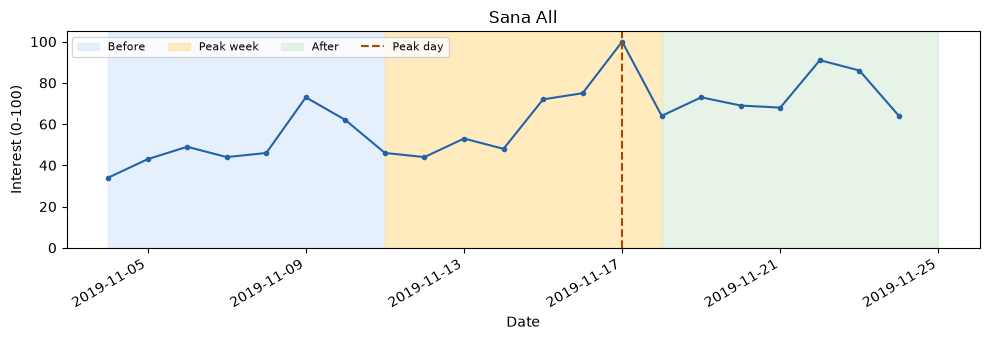

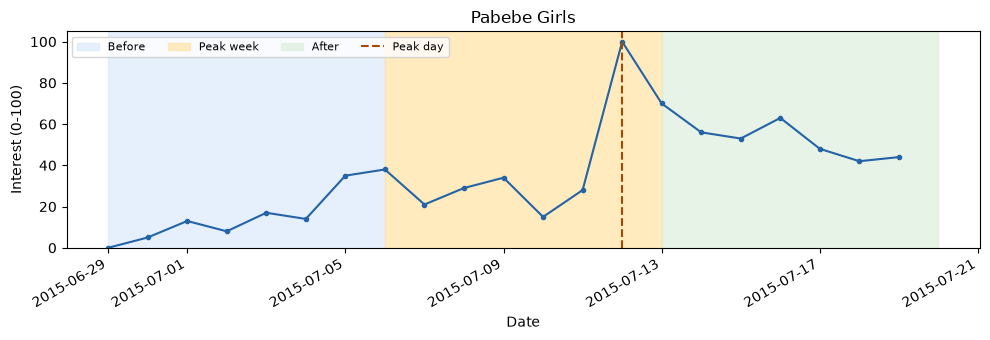

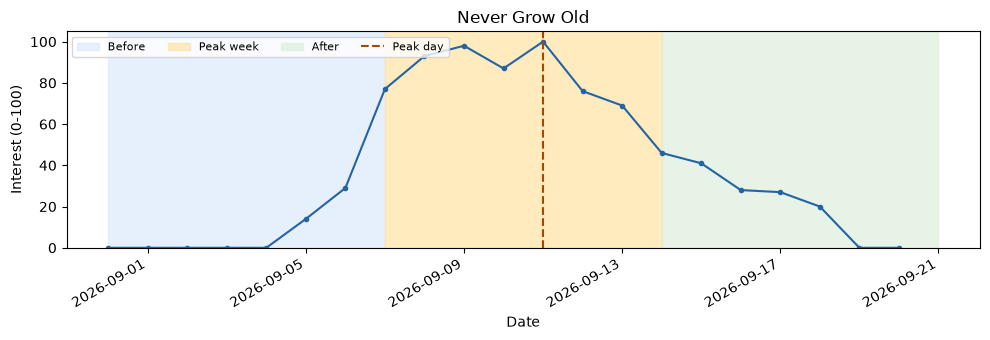

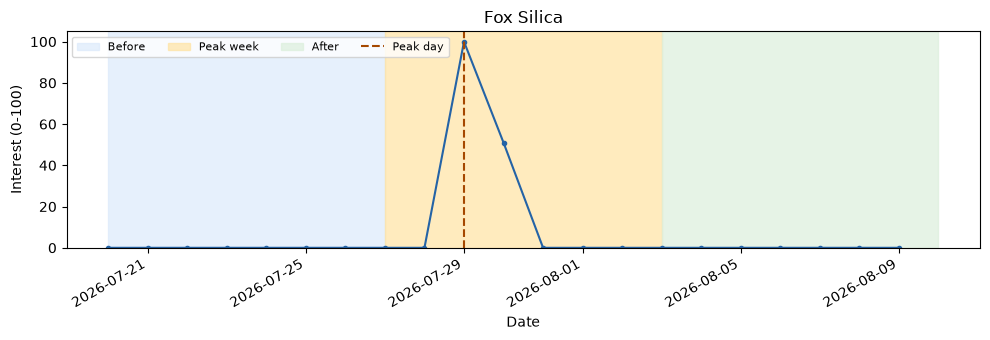

In [16]:
colors = {"Before": "#dceafb", "Peak week": "#ffe3a3", "After": "#dcefdc"}

for trend in trends.itertuples(index=False):
    if trend.slug not in week_windows:
        continue

    windows = week_windows[trend.slug]
    start = windows[0][1]
    end = windows[-1][1] + pd.Timedelta(days=6)
    series = daily_data[trend.slug].reindex(pd.date_range(start, end, freq="D"))

    fig, ax = plt.subplots(figsize=(10, 3.5))
    for label, week_start in windows:
        ax.axvspan(week_start, week_start + pd.Timedelta(days=7),
                   color=colors[label], alpha=0.7, label=label)
    ax.plot(series.index, series, marker="o", markersize=3, color="#2463a6")
    ax.axvline(peak_days[trend.slug], color="#a54800", linestyle="--", label="Peak day")
    ax.set(title=trend.query, xlabel="Date", ylabel="Interest (0-100)", ylim=(0, 105))
    ax.legend(loc="upper left", ncol=4, fontsize=8)
    fig.autofmt_xdate()
    fig.tight_layout()
    plt.show()


## 6. Regional interest

Compare the same three weeks with the last 30 days of the chosen window.
Each panel has its own 0-100 scale. Compare regional ranks, not score changes across panels.
A high score means strong relative interest, not the most searches. [Google's guide](https://support.google.com/trends/answer/4355212?hl=en)

Set `RUN_REGIONS = False` to skip these extra requests.


In [17]:
region_data = {}
region_windows = {}

if RUN_REGIONS:
    for trend in trends.itertuples(index=False):
        if trend.slug not in data:
            continue

        windows = []
        if trend.slug in week_windows:
            for label, start in week_windows[trend.slug]:
                end = start + pd.Timedelta(days=6)
                if end <= pd.Timestamp(END_DATE):
                    windows.append((label, start, end))
                else:
                    print(f"{trend.query}, {label}: week extends beyond END_DATE; skipped.")

        recent_end = pd.Timestamp(END_DATE)
        recent_start = recent_end - pd.Timedelta(days=29)
        windows.append(("Last 30 days", recent_start, recent_end))
        region_windows[trend.slug] = windows

        for label, start, end in windows:
            frame = load_trends(
                trend.slug, trend.query,
                f"{start:%Y-%m-%d}", f"{end:%Y-%m-%d}", kind="region",
            )
            region_data[(trend.slug, label)] = frame
else:
    print("Regional requests skipped.")


Sana All: saved region data (2019-11-04 2019-11-10)
Sana All: saved region data (2019-11-11 2019-11-17)
Sana All: saved region data (2019-11-18 2019-11-24)
Sana All: saved region data (2026-08-27 2026-09-25)
Pabebe Girls: saved region data (2015-06-29 2015-07-05)
Pabebe Girls: saved region data (2015-07-06 2015-07-12)
Pabebe Girls: saved region data (2015-07-13 2015-07-19)
Pabebe Girls: saved region data (2026-08-27 2026-09-25)
Never Grow Old: saved region data (2026-08-31 2026-09-06)
Never Grow Old: saved region data (2026-09-07 2026-09-13)
Never Grow Old: saved region data (2026-09-14 2026-09-20)
Never Grow Old: saved region data (2026-08-27 2026-09-25)
Fox Silica: saved region data (2026-07-20 2026-07-26)
Fox Silica: saved region data (2026-07-27 2026-08-02)
Fox Silica: saved region data (2026-08-03 2026-08-09)
Fox Silica: saved region data (2026-08-27 2026-09-25)


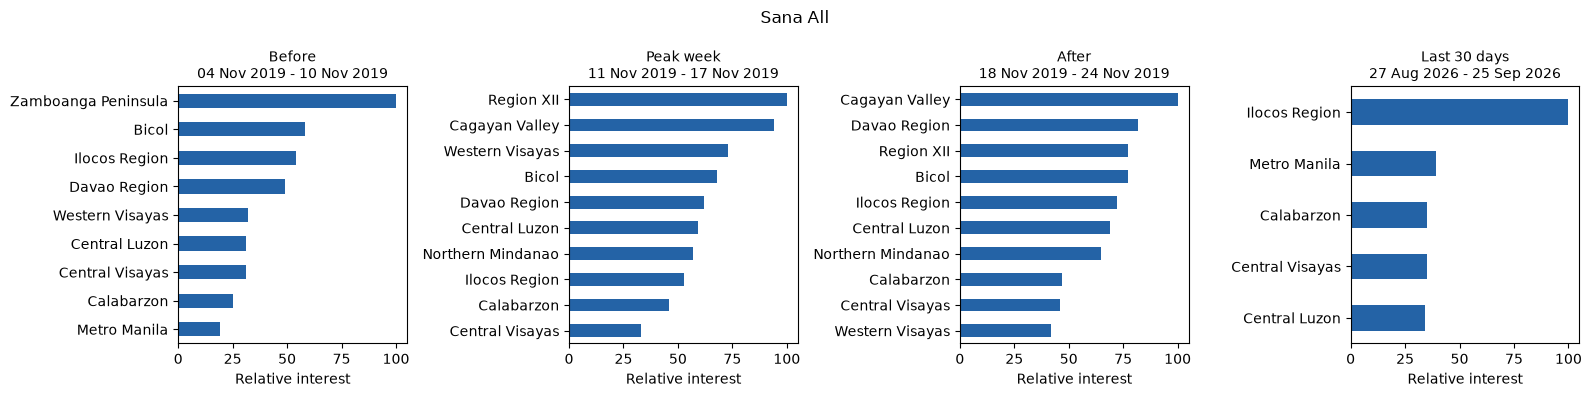

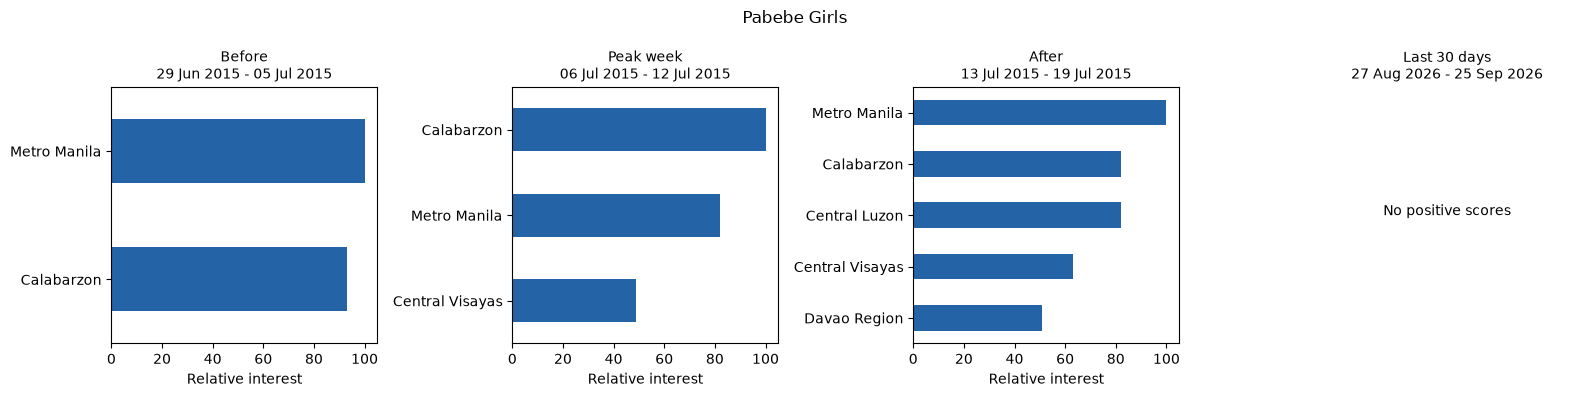

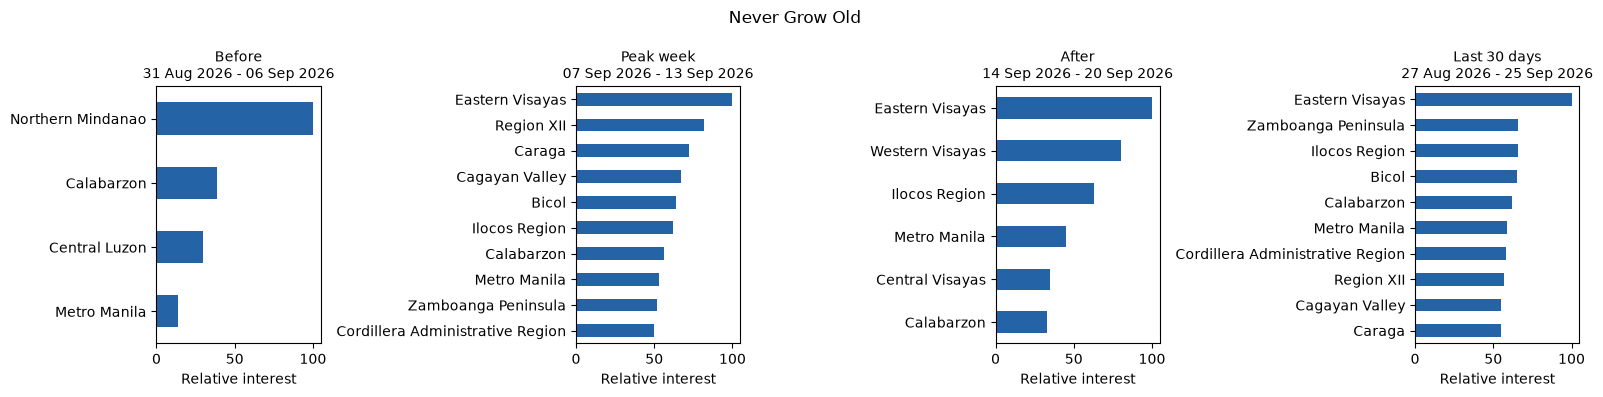

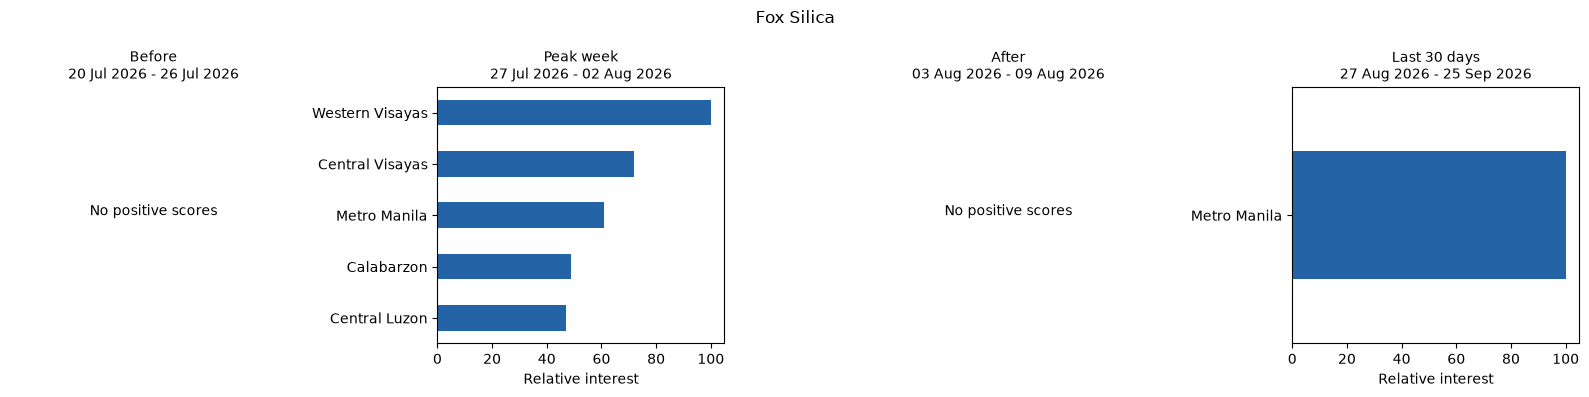

In [18]:
for trend in trends.itertuples(index=False):
    if trend.slug not in region_windows:
        continue

    windows = region_windows[trend.slug]
    fig, axes = plt.subplots(1, len(windows), figsize=(4 * len(windows), 4), squeeze=False)

    for ax, (label, start, end) in zip(axes[0], windows):
        ax.set_title(f"{label}\n{start:%d %b %Y} - {end:%d %b %Y}", fontsize=10)
        frame = region_data.get((trend.slug, label))
        if frame is None or frame.empty:
            ax.text(0.5, 0.5, "No regional data", ha="center", transform=ax.transAxes)
            ax.set_axis_off()
            continue

        scores = pd.to_numeric(frame.iloc[:, 0], errors="coerce")
        top = scores.loc[(scores > 0) & (scores <= 100)].sort_values(ascending=False).head(10)
        if top.empty:
            ax.text(0.5, 0.5, "No positive scores", ha="center", transform=ax.transAxes)
            ax.set_axis_off()
        else:
            top.sort_values().plot.barh(ax=ax, color="#2463a6")
            ax.set(xlabel="Relative interest", ylabel="", xlim=(0, 105))

    fig.suptitle(trend.query)
    fig.tight_layout()
    plt.show()


## 7. What did we find?

Saved run, using data through **25 Sep 2026**:

| Trend | Peak-week mean | Next-week mean | Reading |
|---|---:|---:|---|
| Sana All | 68.9 | 74.9 | Interest stayed high after the peak day. |
| Pabebe Girls | 36.9 | 52.3 | Interest kept rising after the peak day. |
| Never Grow Old | 89.7 | 26.7 | The next week kept about 30% of peak-week interest. |
| Fox Silica | 25.4 | 0.0 | A short spike; check it against other sources. |

These are separate scales. Compare weeks within each term, not scores across terms.
The notes below update when you rerun; this table records the saved run.

### Notes from this run

Use the complete weeks above. The week containing the highest day need not have the highest weekly mean.


In [19]:
if changes.empty:
    print("No weekly findings yet. Load daily data and rerun the comparison.")
else:
    for row in changes.to_dict("records"):
        query = row["Trend"]
        rise = row["Before to peak (points)"]
        later = row["Peak to after (points)"]

        if pd.isna(rise):
            print(f"{query}: before-to-peak comparison needs two complete weeks.")
        elif rise > 0:
            print(f"{query}: peak-week mean rose {rise:.1f} points from the week before.")
        elif rise < 0:
            print(f"{query}: peak-week mean fell {abs(rise):.1f} points from the week before.")
        else:
            print(f"{query}: before and peak-week means were equal.")

        if pd.isna(later):
            print("  After-peak comparison needs two complete weeks.")
        elif later < 0:
            print(f"  The following week's mean fell {abs(later):.1f} points.")
        elif later > 0:
            print(f"  The following week's mean rose {later:.1f} points.")
        else:
            print("  The following week's mean stayed the same.")


Sana All: peak-week mean rose 12.4 points from the week before.
  The following week's mean rose 11.0 points.
Pabebe Girls: peak-week mean rose 24.7 points from the week before.
  The following week's mean rose 15.9 points.
Never Grow Old: peak-week mean rose 79.6 points from the week before.
  The following week's mean fell 62.6 points.
Fox Silica: peak-week mean rose 21.6 points from the week before.
  The following week's mean fell 21.6 points.


## 8. Better datapoints for the ML pipeline

The first ML run trained on one full-history request per term. Google returns **monthly** rows for
windows longer than five years, so the whole Pabebe Girls spike is one row (July 2015 = 100, next month 20),
and the chronological test split lands in the dead tail: its Pabebe test targets were all zero, so the
last-value baseline scored a perfect 0.000. Never Grow Old had 42 daily rows and was skipped.

What this section changes:

| Problem | Fix |
|---|---|
| Monthly rows hide the rise and decay | Request **overlapping windows** short enough for weekly (up to ~5 years) or daily (up to 269 days) rows, then **stitch** them onto one scale using the overlap |
| The training data is mostly the dead tail | Daily series cover each term's **active lifecycle** (rise, peak, decay); weekly series keep the long history |
| Never Grow Old stopped at 25 Sep | Extend to `ML_END_DATE`, which adds about four weeks of decay |
| Google **samples** searches | A pull made on 22 Oct differed from the 14 Oct pull of the same window by **6.5 points** on average. Repeating a request on the same day, or shifting the window by a day, returns the same sample. Every pull is archived by date, and pulls of a window from different days are **averaged** |
| Random zeros in busy periods | Isolated zeros right after a busy week are low-volume **dropouts**, not zero interest (they move between pulls). They become missing, using past values only |

Stitching: each new window is multiplied by `sum(previous overlap) / sum(new overlap)` over overlap
dates where both are positive; overlapping values are averaged; the result is rescaled so its maximum is 100.
The weekly series is checked against the monthly backbone below.

Set `ML_NEW_PULL = True` on a later day to add another sample to every window.

In [20]:
ML_END_DATE = "2026-10-21"  # Last complete day when this section was written.
ML_NEW_PULL = False  # True: add today's sample for every window, if not already archived.
DROPOUT_FLOOR = 10  # A zero after a trailing 7-row median at or above this is a dropout.

PROCESSED_DIR = DATA_DIR / "processed"
PULL_DIR = RAW_DIR / "pulls"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
PULL_DIR.mkdir(parents=True, exist_ok=True)

# Google returns daily rows up to 269 days and weekly rows up to about five years.
WINDOW_DAYS = {"daily": 260, "weekly": 4 * 365}
OVERLAP_DAYS = {"daily": 60, "weekly": 365}

# Daily windows cover the active lifecycle; weekly windows keep the long history.
# Pabebe Girls weekly stops at 2017: later windows are all zeros and cannot be aligned.
stitch_plan = pd.DataFrame([
    {"slug": "sana_all", "query": "Sana All", "freq": "weekly", "start": "2018-01-01", "end": ML_END_DATE},
    {"slug": "sana_all", "query": "Sana All", "freq": "daily", "start": "2019-07-01", "end": "2021-06-30"},
    {"slug": "pabebe_girls", "query": "Pabebe Girls", "freq": "weekly", "start": "2015-01-01", "end": "2017-12-31"},
    {"slug": "pabebe_girls", "query": "Pabebe Girls", "freq": "daily", "start": "2015-05-01", "end": "2016-04-30"},
    {"slug": "never_grow_old", "query": "Never Grow Old", "freq": "daily", "start": "2026-07-15", "end": ML_END_DATE},
])
display(stitch_plan)

,slug,query,freq,start,end
0,sana_all,Sana All,weekly,2018-01-01,2026-10-21
1,sana_all,Sana All,daily,2019-07-01,2021-06-30
2,pabebe_girls,Pabebe Girls,weekly,2015-01-01,2017-12-31
3,pabebe_girls,Pabebe Girls,daily,2015-05-01,2016-04-30
4,never_grow_old,Never Grow Old,daily,2026-07-15,2026-10-21


In [21]:
# Split a long date range into overlapping request windows short enough for daily or weekly rows.
# The last window keeps full length so Google keeps returning the same row frequency.
def plan_windows(start, end, freq):
    start, end = pd.Timestamp(start), pd.Timestamp(end)
    length = pd.Timedelta(days=WINDOW_DAYS[freq] - 1)
    step = pd.Timedelta(days=WINDOW_DAYS[freq] - OVERLAP_DAYS[freq])
    windows = []
    window_start = start
    while window_start + length < end:
        windows.append((window_start, window_start + length))
        window_start += step
    windows.append((max(start, end - length), end))
    return windows


# Turn one saved request into a numeric series.
# Drops unfinished rows and marks zero dropouts (a 0 right after a busy week) as missing,
# using past values only.
def clean_pull(frame):
    frame = frame.copy()
    frame.index = pd.to_datetime(frame.index)
    frame = frame.sort_index()
    if "isPartial" in frame.columns:
        partial = frame.pop("isPartial").astype(str).str.lower() == "true"
        frame = frame.loc[~partial]
    series = pd.to_numeric(frame.iloc[:, 0], errors="coerce")
    series = series.where(series.between(0, 100))
    # Past values only: the decision for a row never reads later rows.
    trailing = series.shift(1).rolling(7, min_periods=4).median()
    dropout = (series == 0) & (trailing >= DROPOUT_FLOOR)
    return series.mask(dropout), int(dropout.sum())


# Fetch or reuse one window, archive it by pull date, and average every archived pull of it.
# Google re-samples between days, so pulls from different days are separate samples.
def collect_pulls(slug, query, start, end):
    start, end = f"{start:%Y-%m-%d}", f"{end:%Y-%m-%d}"
    name = f"{slug}_time_{start}_{end}"
    if load_trends(slug, query, start, end) is None:
        return None, 0, 0

    saved = json.loads((RAW_DIR / f"{name}.json").read_text(encoding="utf-8"))
    archived = PULL_DIR / f"{name}__{saved['extracted_utc'][:10]}.csv"
    if not archived.exists():
        archived.write_bytes((RAW_DIR / f"{name}.csv").read_bytes())

    today = datetime.now(timezone.utc).strftime("%Y-%m-%d")
    today_path = PULL_DIR / f"{name}__{today}.csv"
    if ML_NEW_PULL and not today_path.exists():
        try:
            request_trends(query, f"{start} {end}", "time").to_csv(today_path)
        except Exception as error:
            print(f"{query}, {start} {end}: no new pull ({error})")

    pulls, dropouts = [], 0
    for path in sorted(PULL_DIR.glob(f"{name}__*.csv")):
        series, masked = clean_pull(pd.read_csv(path, index_col=0))
        pulls.append(series)
        dropouts += masked
    return pd.concat(pulls, axis=1, sort=True).mean(axis=1), len(pulls), dropouts


# Join overlapping windows onto one scale: rescale each new window to match the overlap so far,
# average the overlapping days, then rescale the whole series so its maximum is 100.
def stitch(pieces):
    combined = pieces[0]
    for piece in pieces[1:]:
        overlap = combined.index.intersection(piece.index)
        shared = overlap[(combined[overlap] > 0) & (piece[overlap] > 0)]
        if len(shared) < 4:
            raise ValueError("too little nonzero overlap to align windows; shorten the range or widen OVERLAP_DAYS")
        piece = piece * combined[shared].sum() / piece[shared].sum()
        combined = pd.concat([combined, piece], axis=1, sort=True).mean(axis=1)
    return 100 * combined / combined.max()

In [22]:
processed = {}
build_rows = []

for plan in stitch_plan.itertuples(index=False):
    windows = plan_windows(plan.start, plan.end, plan.freq)
    pieces, pull_counts, dropouts = [], [], 0
    for start, end in windows:
        series, count, masked = collect_pulls(plan.slug, plan.query, start, end)
        if series is None:
            break
        pieces.append(series)
        pull_counts.append(count)
        dropouts += masked
    if len(pieces) < len(windows):
        print(f"{plan.query} ({plan.freq}): a window is missing; not built.")
        continue

    expected_days = 1 if plan.freq == "daily" else 7
    if any(piece.index.to_series().diff().dt.days.median() != expected_days for piece in pieces):
        print(f"{plan.query} ({plan.freq}): Google returned a different row frequency; not built.")
        continue
    try:
        combined = stitch(pieces)
    except ValueError as error:
        print(f"{plan.query} ({plan.freq}): {error}")
        continue
    # Keep a regular grid; masked dropouts stay missing.
    combined = combined.asfreq(f"{expected_days}D").rename(plan.query)

    name = f"{plan.slug}_{plan.freq}"
    frame = pd.DataFrame({"interest": combined.round(3)})
    frame.index.name = "date"
    frame.to_csv(PROCESSED_DIR / f"{name}.csv")
    metadata = {
        "query": plan.query, "geo": GEO, "kind": "time", "freq": plan.freq,
        "window": f"{plan.start} {plan.end}",
        "request_windows": [f"{start:%Y-%m-%d} {end:%Y-%m-%d}" for start, end in windows],
        "pulls_per_window": pull_counts, "dropouts_masked": dropouts,
        "built_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    }
    (PROCESSED_DIR / f"{name}.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
    processed[(plan.slug, plan.freq)] = combined
    build_rows.append({
        "Trend": plan.query, "Resolution": plan.freq, "Rows": len(combined),
        "Request windows": len(windows), "Fewest pulls per window": min(pull_counts),
        "Dropouts masked": dropouts, "First row": f"{combined.index.min():%Y-%m-%d}",
        "Last row": f"{combined.index.max():%Y-%m-%d}",
    })

display(pd.DataFrame(build_rows))

Sana All: 209 rows from pytrends
Sana All: 210 rows from pytrends
Sana All: 209 rows from pytrends
Sana All: 260 rows from pytrends
Sana All: 260 rows from pytrends
Sana All: 260 rows from pytrends
Sana All: 260 rows from pytrends
Pabebe Girls: 158 rows from pytrends
Pabebe Girls: 260 rows from pytrends
Pabebe Girls: 260 rows from pytrends
Never Grow Old: 99 rows from pytrends


,Trend,Resolution,Rows,Request windows,Fewest pulls per window,Dropouts masked,First row,Last row
0,Sana All,weekly,459,3,1,0,2017-12-31,2026-10-11
1,Sana All,daily,731,4,1,163,2019-07-01,2021-06-30
2,Pabebe Girls,weekly,158,1,1,0,2014-12-28,2017-12-31
3,Pabebe Girls,daily,366,2,1,1,2015-05-01,2016-04-30
4,Never Grow Old,daily,99,1,1,4,2026-07-15,2026-10-21


### How many useful datapoints?

`Rows >= 10% of peak` counts rows where the trend is visibly alive. That is where a forecaster has
something to learn; rows near zero mostly teach it to predict zero.

In [23]:
resolution_rows = []
for trend in trends.itertuples(index=False):
    candidates = {
        "original pull (section 3)": data.get(trend.slug),
        "weekly (stitched)": processed.get((trend.slug, "weekly")),
        "daily (stitched)": processed.get((trend.slug, "daily")),
    }
    for label, series in candidates.items():
        if series is None:
            continue
        valid = series.dropna()
        resolution_rows.append({
            "Trend": trend.query, "Series": label, "Rows": len(series),
            "Missing (dropouts)": int(series.isna().sum()),
            "Rows >= 10% of peak": int((valid >= 0.1 * valid.max()).sum()),
            "Rows >= 50% of peak": int((valid >= 0.5 * valid.max()).sum()),
        })

display(pd.DataFrame(resolution_rows))

,Trend,Series,Rows,Missing (dropouts),Rows >= 10% of peak,Rows >= 50% of peak
0,Sana All,original pull (section 3),105,0,43,2
1,Sana All,weekly (stitched),459,0,121,9
2,Sana All,daily (stitched),731,108,428,52
3,Pabebe Girls,original pull (section 3),141,0,2,1
4,Pabebe Girls,weekly (stitched),158,0,7,1
5,Pabebe Girls,daily (stitched),366,0,34,5
6,Never Grow Old,original pull (section 3),42,0,16,7
7,Never Grow Old,daily (stitched),99,4,18,8
8,Fox Silica,original pull (section 3),73,0,2,2


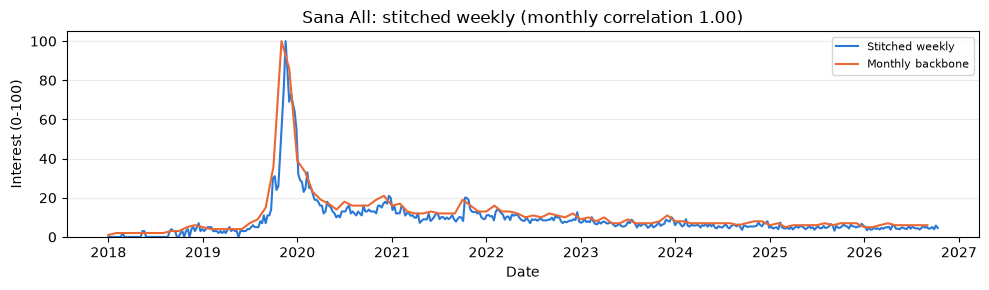

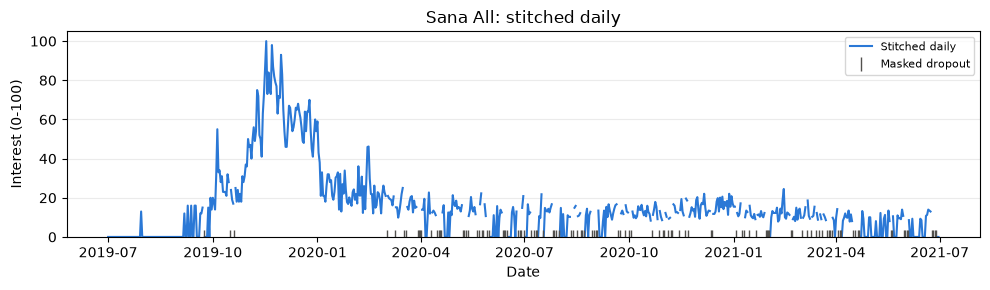

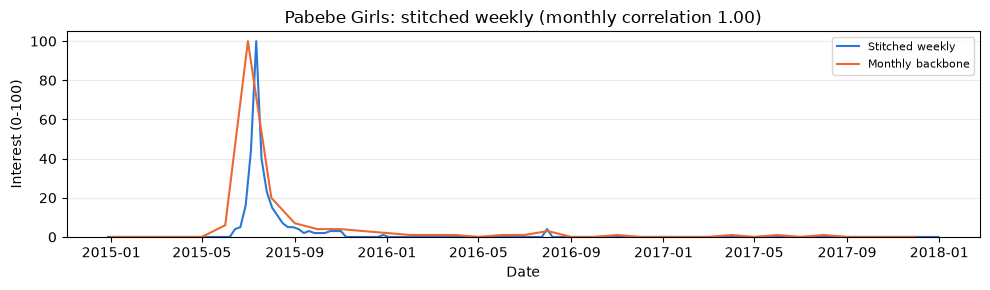

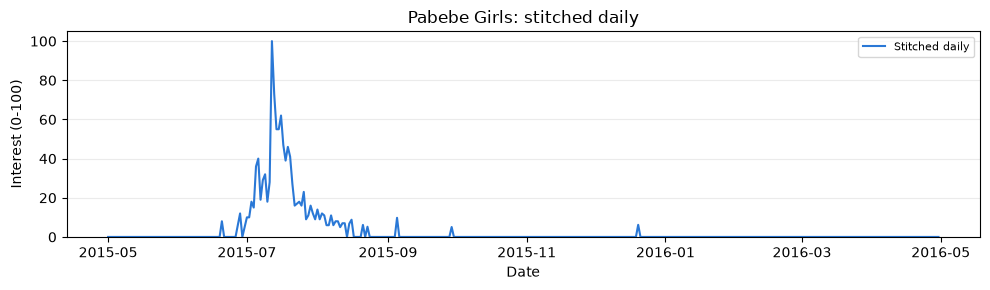

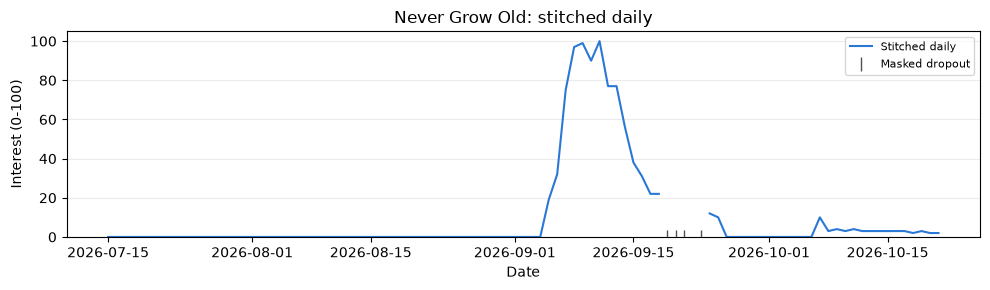

In [24]:
for (slug, freq), series in processed.items():
    fig, ax = plt.subplots(figsize=(10, 3))
    title = f"{series.name}: stitched {freq}"
    ax.plot(series.index, series, color="#2a78d6", linewidth=1.5, label=f"Stitched {freq}")

    if freq == "weekly" and slug in data:
        # Same shape check: weekly averaged to months against the one-request monthly backbone.
        monthly = series.resample("MS").mean()
        monthly = 100 * monthly / monthly.max()
        backbone = data[slug].loc[series.index.min():series.index.max()]
        ax.plot(backbone.index, backbone, color="#eb6834", linewidth=1.5, label="Monthly backbone")
        title += f" (monthly correlation {monthly.corr(backbone):.2f})"

    masked = series.index[series.isna()]
    if len(masked):
        ax.plot(masked, [0] * len(masked), linestyle="none", marker="|", markersize=10,
                color="#52514e", label="Masked dropout")
    ax.set(title=title, xlabel="Date", ylabel="Interest (0-100)", ylim=(0, 105))
    ax.legend(loc="upper right", fontsize=8)
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()
    plt.show()

## 9. Forecasting with the better datapoints

Predict the next period from the previous `lookback` periods with the same small network as before:
one hidden layer of 16, AdamW, CUDA only, chronological **60% train / 20% validation / 20% test**,
checkpoint chosen on validation loss, test MAE compared with the last observed value.
Evaluation is one step ahead with observed past values, as before.

What changes is the data it sees:

- **Resolution.** Each term is trained on the monthly backbone (the original run), the stitched weekly
  series and the stitched daily lifecycle, so the gain from finer data is measured rather than assumed.
- **Never Grow Old.** Its daily series now runs to `ML_END_DATE`, covering the rise, peak and decay,
  and clears the 80-window minimum. Fox Silica is left out: its series is almost entirely zeros.
- **Dropouts.** Masked zeros stay missing. Inputs carry the last observed value forward (past only);
  missing targets are neither trained on nor scored.
- **Honest scores.** `Test zero share` flags holdouts that are mostly zeros, where a constant looks
  perfect. `Skill (%)` is the improvement over the last-value baseline; negative means worse.

Daily series use 14 lags (two weeks, so weekday effects are visible); weekly and monthly use 12.
Each stitched series is on its own 0-100 scale; compare a model with its own baseline, not across terms.

In [25]:
import copy
import numpy as np

# Read a cached single-query CSV as a regular time series.
# Uses its metadata to drop unfinished weeks/months and to reject regional snapshots.
def load_series(path, column=None):
    path = Path(path)
    frame = pd.read_csv(path, index_col=0)
    frame.index = pd.to_datetime(frame.index, errors="raise")
    partial = pd.Series(False, index=frame.index)
    if "isPartial" in frame:
        partial = frame.pop("isPartial").astype(str).str.lower().isin(["true", "1"])
    if column is None:
        if len(frame.columns) != 1:
            raise ValueError("Pass column= for a multi-term CSV.")
        column = frame.columns[0]
    series = pd.to_numeric(frame[column].astype(str).str.strip().replace(
        {"<1": "0.5", "< 1": "0.5"}), errors="coerce")
    series.loc[partial] = np.nan
    series = series.sort_index()
    if series.index.has_duplicates or len(series) < 3:
        raise ValueError("Need at least three unique date rows.")
    freq = pd.infer_freq(series.index)
    if freq is None:
        raise ValueError("CSV must have regular daily, weekly, or monthly dates; retain missing rows as NaN.")
    offset = pd.tseries.frequencies.to_offset(freq)
    if not (freq == "D" or freq.startswith("W-") or freq == "MS"):
        raise ValueError(f"Unsupported frequency {freq}; expected daily, weekly, or month-start.")
    metadata_path = path.with_suffix(".json")
    if metadata_path.exists():
        metadata = json.loads(metadata_path.read_text(encoding="utf-8"))
        if metadata.get("kind", "time") != "time":
            raise ValueError("Regional snapshots are not temporal training data.")
        window = metadata.get("window", "").split()
        if len(window) == 2:
            start, end = map(pd.Timestamp, window)
            series = series.loc[start:end]
            # A monthly/weekly row describes a whole period, not just its first day.
            complete = series.index + offset - pd.Timedelta(days=1) <= end
            series = series.loc[complete]
    return series


# Turn a series into supervised rows: the previous `lookback` values (x) -> the next value (y), scaled 0-1.
# Missing values are carried forward as inputs but never used as targets.
def make_windows(series, lookback=12):
    if lookback < 2:
        raise ValueError("lookback must be at least 2.")
    if not isinstance(series.index, pd.DatetimeIndex) or series.index.has_duplicates:
        raise ValueError("Expected a unique DatetimeIndex.")
    series = series.sort_index()
    if pd.infer_freq(series.index) is None:
        raise ValueError("Use a regular date grid; missing observations must stay NaN.")
    values = series.to_numpy(dtype=np.float32)
    # Inputs carry the last observed value forward (past only); missing targets are skipped.
    filled = series.ffill().to_numpy(dtype=np.float32)
    x, y, dates = [], [], []
    for target in range(lookback, len(values)):
        window = filled[target - lookback:target]
        if not (np.isfinite(window).all() and np.isfinite(values[target])):
            continue
        if ((window >= 0) & (window <= 100)).all() and 0 <= values[target] <= 100:
            x.append(window / 100.0)
            y.append(values[target] / 100.0)
            dates.append(series.index[target])
    if not x:
        raise ValueError("No complete valid lag windows.")
    return np.asarray(x), np.asarray(y), pd.DatetimeIndex(dates)


# Train the small MLP on the GPU with a chronological 60/20/20 split.
# Keeps the epoch with the lowest validation loss, then scores one-step test predictions
# against the last-value baseline. Returns the model, a metrics report and the predictions.
def train_forecaster(series, lookback=12, epochs=300, seed=42, min_windows=80):
    device = require_cuda()
    if epochs < 1:
        raise ValueError("epochs must be positive.")
    x, y, dates = make_windows(series, lookback)
    if len(y) < min_windows:
        raise ValueError(f"Only {len(y)} complete windows; need at least {min_windows}. Collect more history.")
    train_end, val_end = int(len(y) * 0.6), int(len(y) * 0.8)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    # Fixed /100 scaling needs no fitted statistics from future observations.
    inputs = torch.as_tensor(x, device=device)
    targets = torch.as_tensor(y, device=device)
    model = torch.nn.Sequential(torch.nn.Linear(lookback, 16), torch.nn.ReLU(),
                                torch.nn.Linear(16, 1)).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.003, weight_decay=0.01)
    best_loss, best_state, stale, best_epoch = float("inf"), None, 0, 0
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad(set_to_none=True)
        loss = torch.nn.functional.mse_loss(model(inputs[:train_end]).squeeze(-1), targets[:train_end])
        loss.backward()
        optimizer.step()
        model.eval()
        with torch.no_grad():
            validation = torch.nn.functional.mse_loss(
                model(inputs[train_end:val_end]).squeeze(-1), targets[train_end:val_end]).item()
        if not np.isfinite(validation):
            raise RuntimeError("Non-finite validation loss.")
        if validation < best_loss:
            best_loss, best_state = validation, copy.deepcopy(model.state_dict())
            stale, best_epoch = 0, epoch + 1
        else:
            stale += 1
            if stale >= 30:
                break
    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        predicted = model(inputs[val_end:]).squeeze(-1).clamp(0, 1).cpu().numpy() * 100
    actual, baseline = y[val_end:] * 100, x[val_end:, -1] * 100
    predictions = pd.DataFrame({"actual": actual, "predicted": predicted,
                                "last_value_baseline": baseline}, index=dates[val_end:])
    predictions.index.name = "date"
    model_mae = float(np.abs(actual - predicted).mean())
    baseline_mae = float(np.abs(actual - baseline).mean())
    report = {
        "device": str(next(model.parameters()).device), "gpu": torch.cuda.get_device_name(device),
        "torch": torch.__version__, "cuda_runtime": torch.version.cuda,
        "seed": seed, "lookback": lookback, "best_epoch": best_epoch,
        "train_windows": train_end, "validation_windows": val_end - train_end,
        "test_windows": len(y) - val_end, "train_last_target": str(dates[train_end - 1]),
        "validation_first_target": str(dates[train_end]), "test_first_target": str(dates[val_end]),
        "test_last_target": str(dates[-1]), "model_mae_index_points": model_mae,
        "model_rmse_index_points": float(np.sqrt(((actual - predicted) ** 2).mean())),
        "baseline_mae_index_points": baseline_mae, "beats_baseline": model_mae < baseline_mae,
        "skill_vs_baseline_pct": 100 * (1 - model_mae / baseline_mae) if baseline_mae > 0 else float("nan"),
        "test_zero_share": float((actual == 0).mean()),
        "evaluation": "one-step walk-forward with observed past lags; no test-set fitting",
    }
    return model, report, predictions

In [26]:
# Settings: change these before running the experiment.
ML_LOOKBACK = {"monthly": 12, "weekly": 12, "daily": 14}
ML_EPOCHS = 300
ML_SEED = 42
ML_MIN_WINDOWS = 80
ML_SAVE_ARTIFACTS = False  # Results always remain visible in this notebook.
ML_ARTIFACT_DIR = Path("artifacts")

# Monthly: the original full-history caches. Weekly and daily: section 8's stitched series.
ml_terms = [
    ("sana_all", "Sana All", "2018-01-01"),
    ("pabebe_girls", "Pabebe Girls", "2015-01-01"),
    ("never_grow_old", "Never Grow Old", None),
]
ml_end_date = globals().get("END_DATE", "2026-09-25")
ml_series = {}
ml_sources = []
for slug, query, start in ml_terms:
    paths = {}
    if start is not None:
        paths["monthly"] = RAW_DIR / f"{slug}_time_{start}_{ml_end_date}.csv"
    for freq in ("weekly", "daily"):
        if ((stitch_plan["slug"] == slug) & (stitch_plan["freq"] == freq)).any():
            paths[freq] = PROCESSED_DIR / f"{slug}_{freq}.csv"

    for resolution, path in paths.items():
        if not path.exists():
            print(f"{query} ({resolution}): {path} is missing. Run section 8 first.")
            continue
        try:
            series = load_series(path).rename(query)
        except ValueError as error:
            print(f"{query} ({resolution}): skipped ({error})")
            continue
        ml_series[(slug, resolution)] = series
        ml_sources.append({"Trend": query, "Resolution": resolution, "CSV": str(path),
                           "Rows": len(series), "Missing": int(series.isna().sum()),
                           "First row": f"{series.index.min():%Y-%m-%d}",
                           "Last row": f"{series.index.max():%Y-%m-%d}"})
display(pd.DataFrame(ml_sources))

,Trend,Resolution,CSV,Rows,Missing,First row,Last row
0,Sana All,monthly,data\raw\sana_all_time_2018-01-01_2026-09-25.csv,104,0,2018-01-01,2026-08-01
1,Sana All,weekly,data\processed\sana_all_weekly.csv,458,0,2018-01-07,2026-10-11
2,Sana All,daily,data\processed\sana_all_daily.csv,731,108,2019-07-01,2021-06-30
3,Pabebe Girls,monthly,data\raw\pabebe_girls_time_2015-01-01_2026-09-...,140,0,2015-01-01,2026-08-01
4,Pabebe Girls,weekly,data\processed\pabebe_girls_weekly.csv,156,0,2015-01-04,2017-12-24
5,Pabebe Girls,daily,data\processed\pabebe_girls_daily.csv,366,0,2015-05-01,2016-04-30
6,Never Grow Old,daily,data\processed\never_grow_old_daily.csv,99,4,2026-07-15,2026-10-21


In [27]:
ml_results = {}
ml_summary_rows = []
for (slug, resolution), series in ml_series.items():
    try:
        model, metrics, predictions = train_forecaster(
            series, lookback=ML_LOOKBACK[resolution], epochs=ML_EPOCHS, seed=ML_SEED,
            min_windows=ML_MIN_WINDOWS)
    except ValueError as error:
        print(f"{series.name} ({resolution}): skipped ({error})")
        continue
    ml_results[(slug, resolution)] = {"model": model, "metrics": metrics, "predictions": predictions}
    ml_summary_rows.append({"Trend": series.name, "Resolution": resolution, "Device": metrics["device"],
                            "Windows": metrics["train_windows"] + metrics["validation_windows"] + metrics["test_windows"],
                            "Test periods": metrics["test_windows"],
                            "Test zero share": metrics["test_zero_share"],
                            "Model MAE": metrics["model_mae_index_points"],
                            "Last-value MAE": metrics["baseline_mae_index_points"],
                            "Skill (%)": metrics["skill_vs_baseline_pct"],
                            "Beats baseline": metrics["beats_baseline"]})
    if ML_SAVE_ARTIFACTS:
        output = ML_ARTIFACT_DIR / f"{slug}_{resolution}"
        output.mkdir(parents=True, exist_ok=True)
        torch.save({"state_dict": model.state_dict(), "report": metrics}, output / "model.pt")
        predictions.to_csv(output / "test_predictions.csv")
        (output / "metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
ml_summary = pd.DataFrame(ml_summary_rows)
display(ml_summary.round(3))
if ml_summary.empty:
    print("No eligible training series. Run section 8, or collect more complete observations.")

,Trend,Resolution,Device,Windows,Test periods,Test zero share,Model MAE,Last-value MAE,Skill (%),Beats baseline
0,Sana All,monthly,cuda:0,92,19,0.000,0.518,0.632,17.958,True
1,Sana All,weekly,cuda:0,446,90,0.000,0.697,0.851,18.012,True
2,Sana All,daily,cuda:0,609,122,0.295,4.002,3.884,-3.046,False
3,Pabebe Girls,monthly,cuda:0,128,26,1.000,0.012,0.000,NaN,False
4,Pabebe Girls,weekly,cuda:0,144,29,1.000,0.000,0.000,NaN,False
5,Pabebe Girls,daily,cuda:0,352,71,1.000,0.035,0.000,NaN,False
6,Never Grow Old,daily,cuda:0,81,17,0.118,8.469,1.412,-499.869,False


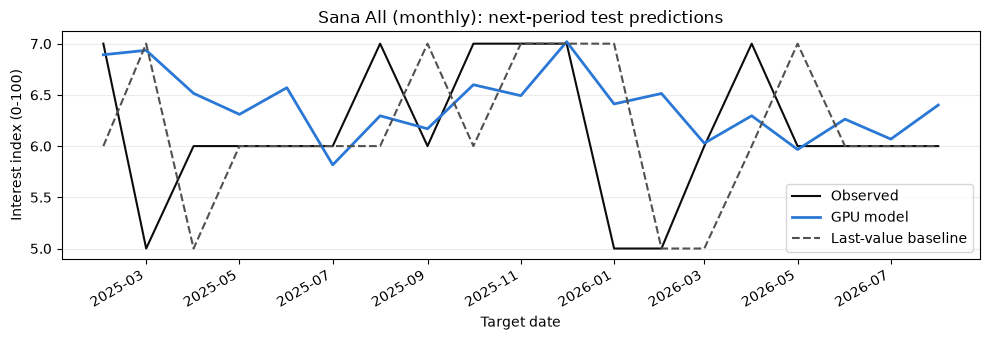

device                                                                  cuda:0
gpu                                         NVIDIA GeForce RTX 5050 Laptop GPU
torch                                                             2.13.0+cu130
cuda_runtime                                                              13.0
seed                                                                        42
lookback                                                                    12
best_epoch                                                                  60
train_windows                                                               55
validation_windows                                                          18
test_windows                                                                19
train_last_target                                          2023-07-01 00:00:00
validation_first_target                                    2023-08-01 00:00:00
test_first_target                                   

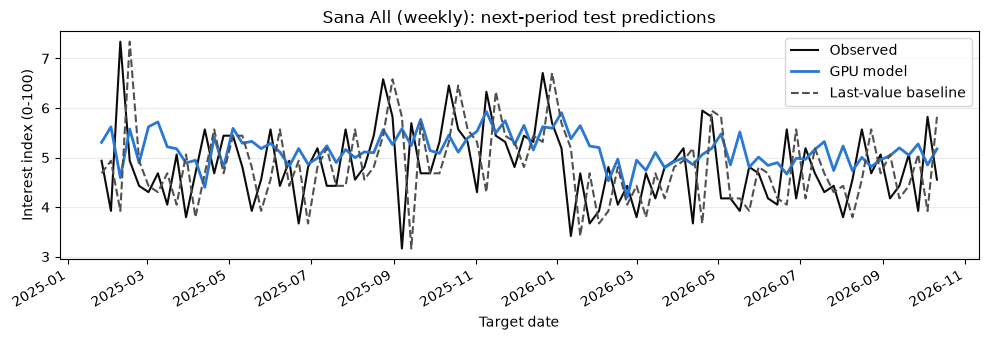

device                                                                  cuda:0
gpu                                         NVIDIA GeForce RTX 5050 Laptop GPU
torch                                                             2.13.0+cu130
cuda_runtime                                                              13.0
seed                                                                        42
lookback                                                                    12
best_epoch                                                                  62
train_windows                                                              267
validation_windows                                                          89
test_windows                                                                90
train_last_target                                          2023-05-07 00:00:00
validation_first_target                                    2023-05-14 00:00:00
test_first_target                                   

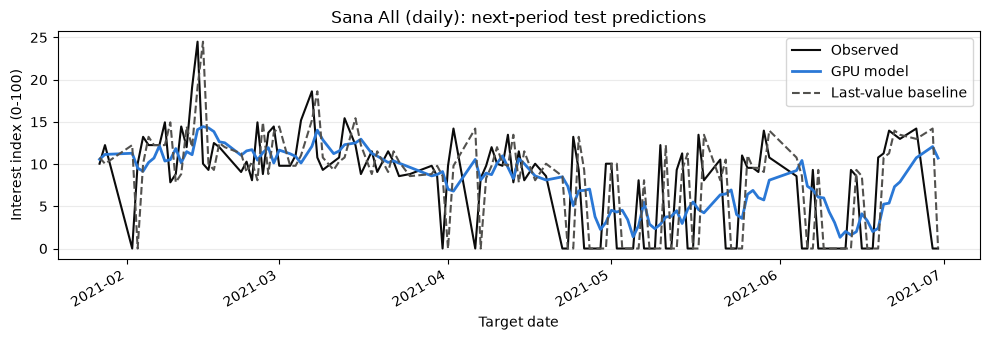

device                                                                  cuda:0
gpu                                         NVIDIA GeForce RTX 5050 Laptop GPU
torch                                                             2.13.0+cu130
cuda_runtime                                                              13.0
seed                                                                        42
lookback                                                                    14
best_epoch                                                                  80
train_windows                                                              365
validation_windows                                                         122
test_windows                                                               122
train_last_target                                          2020-09-04 00:00:00
validation_first_target                                    2020-09-05 00:00:00
test_first_target                                   

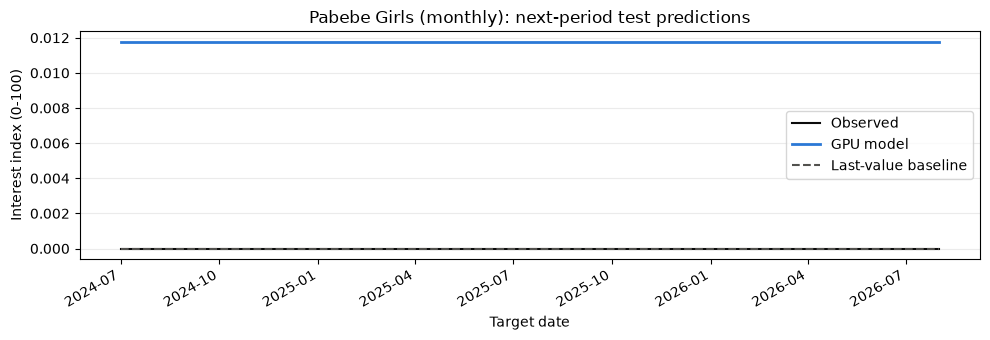

device                                                                  cuda:0
gpu                                         NVIDIA GeForce RTX 5050 Laptop GPU
torch                                                             2.13.0+cu130
cuda_runtime                                                              13.0
seed                                                                        42
lookback                                                                    12
best_epoch                                                                  75
train_windows                                                               76
validation_windows                                                          26
test_windows                                                                26
train_last_target                                          2022-04-01 00:00:00
validation_first_target                                    2022-05-01 00:00:00
test_first_target                                   

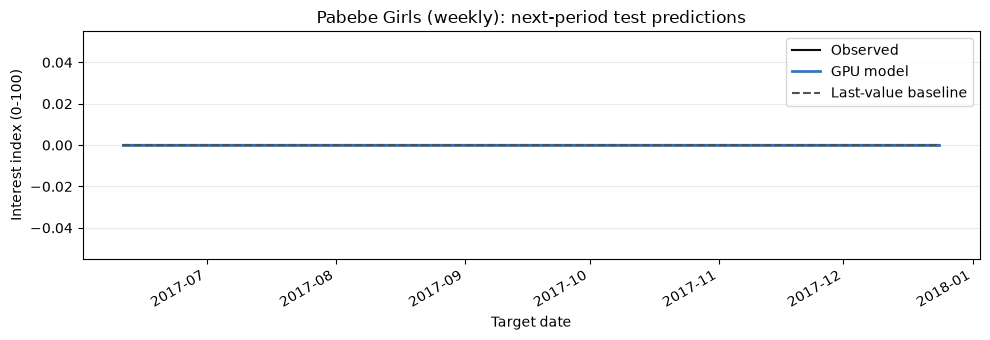

device                                                                  cuda:0
gpu                                         NVIDIA GeForce RTX 5050 Laptop GPU
torch                                                             2.13.0+cu130
cuda_runtime                                                              13.0
seed                                                                        42
lookback                                                                    12
best_epoch                                                                  29
train_windows                                                               86
validation_windows                                                          29
test_windows                                                                29
train_last_target                                          2016-11-13 00:00:00
validation_first_target                                    2016-11-20 00:00:00
test_first_target                                   

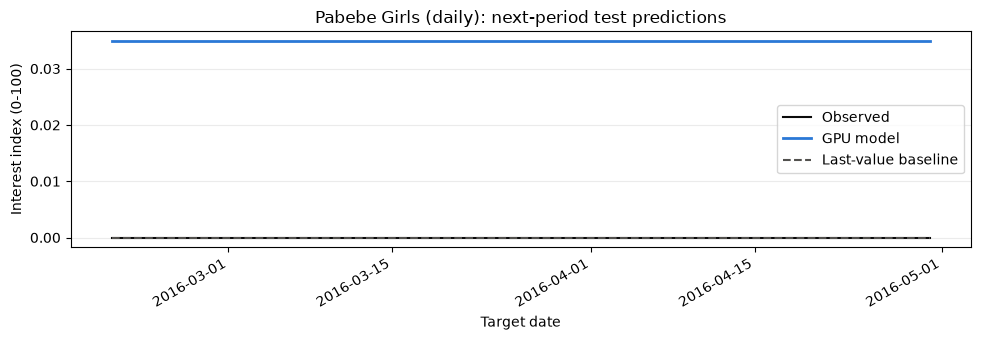

device                                                                  cuda:0
gpu                                         NVIDIA GeForce RTX 5050 Laptop GPU
torch                                                             2.13.0+cu130
cuda_runtime                                                              13.0
seed                                                                        42
lookback                                                                    14
best_epoch                                                                  41
train_windows                                                              211
validation_windows                                                          70
test_windows                                                                71
train_last_target                                          2015-12-11 00:00:00
validation_first_target                                    2015-12-12 00:00:00
test_first_target                                   

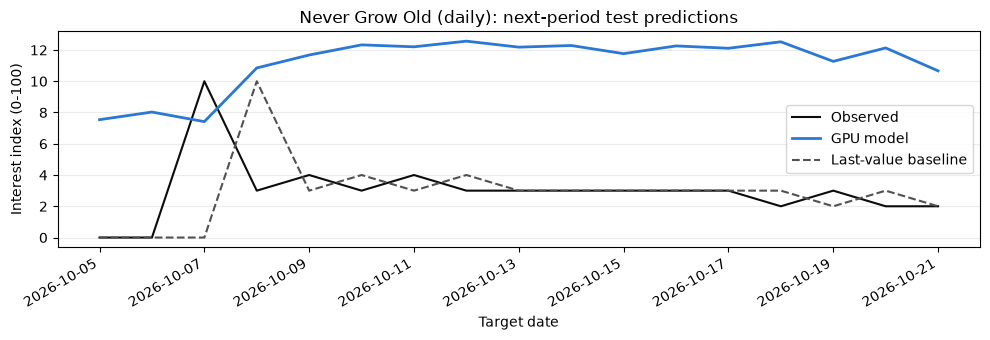

device                                                                  cuda:0
gpu                                         NVIDIA GeForce RTX 5050 Laptop GPU
torch                                                             2.13.0+cu130
cuda_runtime                                                              13.0
seed                                                                        42
lookback                                                                    14
best_epoch                                                                  19
train_windows                                                               48
validation_windows                                                          16
test_windows                                                                17
train_last_target                                          2026-09-14 00:00:00
validation_first_target                                    2026-09-15 00:00:00
test_first_target                                   

In [28]:
for (slug, resolution), result in ml_results.items():
    predictions = result["predictions"]
    fig, ax = plt.subplots(figsize=(10, 3.5))
    ax.plot(predictions.index, predictions["actual"], label="Observed", color="#0b0b0b", linewidth=1.5)
    ax.plot(predictions.index, predictions["predicted"], label="GPU model", color="#2a78d6", linewidth=2)
    ax.plot(predictions.index, predictions["last_value_baseline"], label="Last-value baseline",
            color="#52514e", linestyle="--")
    ax.set(title=f"{ml_series[(slug, resolution)].name} ({resolution}): next-period test predictions",
           xlabel="Target date", ylabel="Interest index (0-100)")
    ax.legend()
    ax.grid(axis="y", alpha=0.25)
    fig.autofmt_xdate()
    fig.tight_layout()
    plt.show()
    display(pd.Series(result["metrics"], name="Evaluation details"))

### Reading the experiment

Compare each model with its own last-value baseline, within that series' scale.
The first monthly run gave Sana All MAE 0.583 versus baseline 0.632, and Pabebe Girls 0.035 versus 0.000
on an all-zero holdout. Neither says much: the monthly test splits held only the dead tail.

When reading the new table:

- A row with a **high test zero share** is a tail test; skill there is not forecasting skill.
- **Daily** rows test the trend while it is still moving; that is where skill matters most.
- Errors near **6 points** are close to Google's own sampling noise between pull days (section 8),
  so differences smaller than that are not meaningful until more pulls are averaged.

`google_trends_ml.ipynb` reruns this comparison against ARIMA, XGBoost and random forests,
adds multi-step forecasts, and tests whether one term's decay can be forecast from the others.